# 01 · Datos, partición temporal y deriva

284.807 transacciones de titulares europeos en **dos días** de septiembre de 2013 (ULB / Worldline). `V1`–`V28` son componentes PCA anónimas; solo `Time` (segundos desde la primera transacción) y `Amount` (EUR) conservan su significado. El fraude es el **0,17 %**.

In [1]:
import json, os, sys, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
RAIZ = Path.cwd() if (Path.cwd() / 'src').is_dir() else Path.cwd().parent  # raíz del proyecto o notebooks/
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ / 'src'))
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
pd.set_option('display.width', 160)
R = RAIZ / 'reports'
res = json.loads((R / 'resultados.json').read_text(encoding='utf-8'))

In [2]:
from fraude.datos import cargar, particion_temporal
df = cargar()
print(f"{len(df):,} transacciones · {int(df.Class.sum())} fraudes · tasa {df.Class.mean()*100:.3f} %")
df.groupby('Class')['Amount'].describe()

284,807 transacciones · 492 fraudes · tasa 0.173 %


,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,"284,315.0000",88.2910,250.1051,0.0000,5.6500,22.0000,77.0500,"25,691.1600"
1,492.0000,122.2113,256.6833,0.0000,1.0000,9.2500,105.8900,"2,125.8700"


## Partición temporal (sin barajar)

En producción el modelo puntúa transacciones **futuras** con lo aprendido del **pasado**. Una partición aleatoria mezclaría minutos del día 2 en el entrenamiento y sobreestimaría el rendimiento, porque los fraudes llegan en ráfagas (el mismo patrón de ataque se repite en minutos). Se corta por *valores* de `Time`: 60 % / 20 % / 20 %.

In [3]:
part = particion_temporal(df)
display(part.resumen())
# Comprobaciones de fuga: los rangos de tiempo no se solapan y ninguna fila está en dos particiones
assert part.entrenamiento.Time.max() < part.validacion.Time.min() <= part.validacion.Time.max() < part.prueba.Time.min()
assert len(part.entrenamiento) + len(part.validacion) + len(part.prueba) == len(df)
print('Sin solapamiento temporal ✔')

,particion,desde_h,hasta_h,horas,transacciones,fraudes,tasa_fraude_pct,monto_fraude_eur
0,entrenamiento,0.0000,33.4400,33.4400,170882,360,0.2107,"40,167.6200"
1,validacion,33.4400,40.3500,6.9000,56963,57,0.1001,"12,231.0900"
2,prueba,40.3500,48.0000,7.6500,56962,75,0.1317,"7,729.2600"


Sin solapamiento temporal ✔


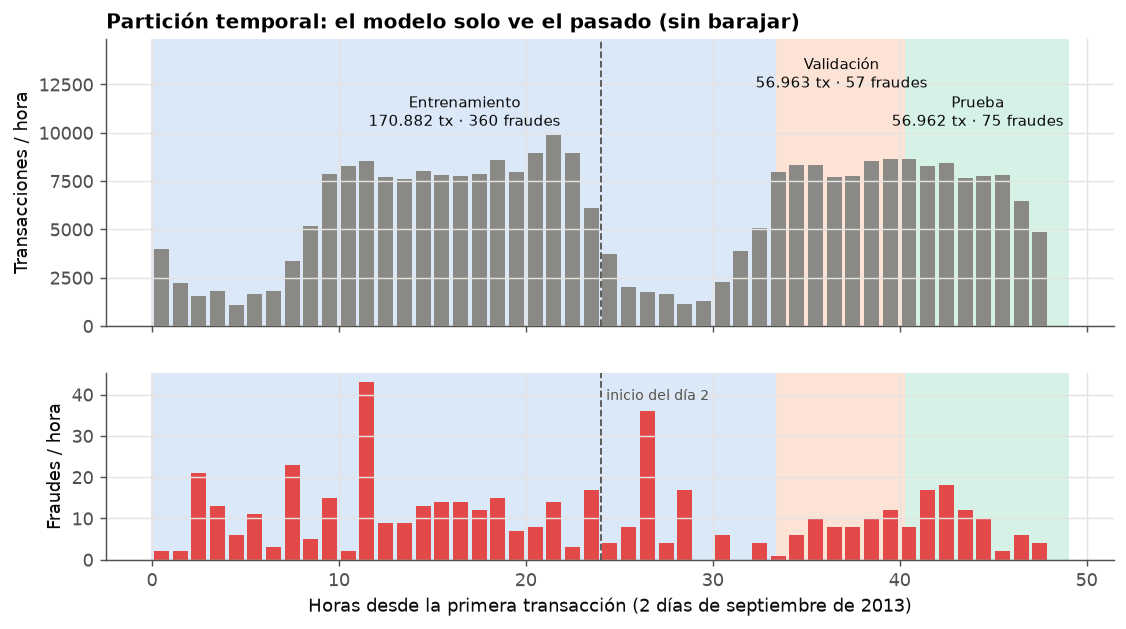

In [4]:
display(Image(filename=str(R / 'figures' / '01_particion_temporal.png')))

## Deriva entre el día 1 y el día 2

PSI y KS por variable sobre transacciones normales, más una *validación adversaria*: un clasificador intenta adivinar el día a partir de `V1`–`V28` y el monto.

In [5]:
display(pd.read_csv(R / 'deriva_variables.csv').head(8))
adv = res['deriva']['adversaria']
print(f"Validación adversaria ROC-AUC = {adv['roc_auc']:.3f}; variables que más delatan el día: {list(adv['top_variables'])}")
print('|corr(V, Time)| en normales:', {k: round(v, 2) for k, v in res['deriva']['corr_time_top'].items()})
display(pd.read_csv(R / 'fraude_por_dia.csv'))

,variable,ks,ks_pvalor,psi,media_dia1,media_dia2
0,V1,0.4232,0.0000,1.5713,-0.2438,0.2688
1,V3,0.5198,0.0000,1.4330,0.6869,-0.6852
2,V28,0.3610,0.0000,1.0495,0.0020,-0.0023
3,V25,0.2959,0.0000,0.4403,0.1303,-0.1349
4,V15,0.2772,0.0000,0.3999,0.2306,-0.2380
5,V5,0.2682,0.0000,0.3540,-0.2745,0.2948
6,V22,0.2200,0.0000,0.3393,-0.1184,0.1223
7,V11,0.1744,0.0000,0.3095,0.1992,-0.2192


Validación adversaria ROC-AUC = 0.995; variables que más delatan el día: ['V1', 'V3', 'V25', 'V24', 'V5']
|corr(V, Time)| en normales: {'V3': 0.44, 'V11': 0.25, 'V25': 0.23, 'V15': 0.18, 'V5': 0.17}


,dia,transacciones,fraudes,tasa_fraude_pct,monto_mediano_normal,monto_mediano_fraude
0,1,144786,281,0.1941,23.4000,9.9900
1,2,140021,211,0.1507,20.3300,9.2100


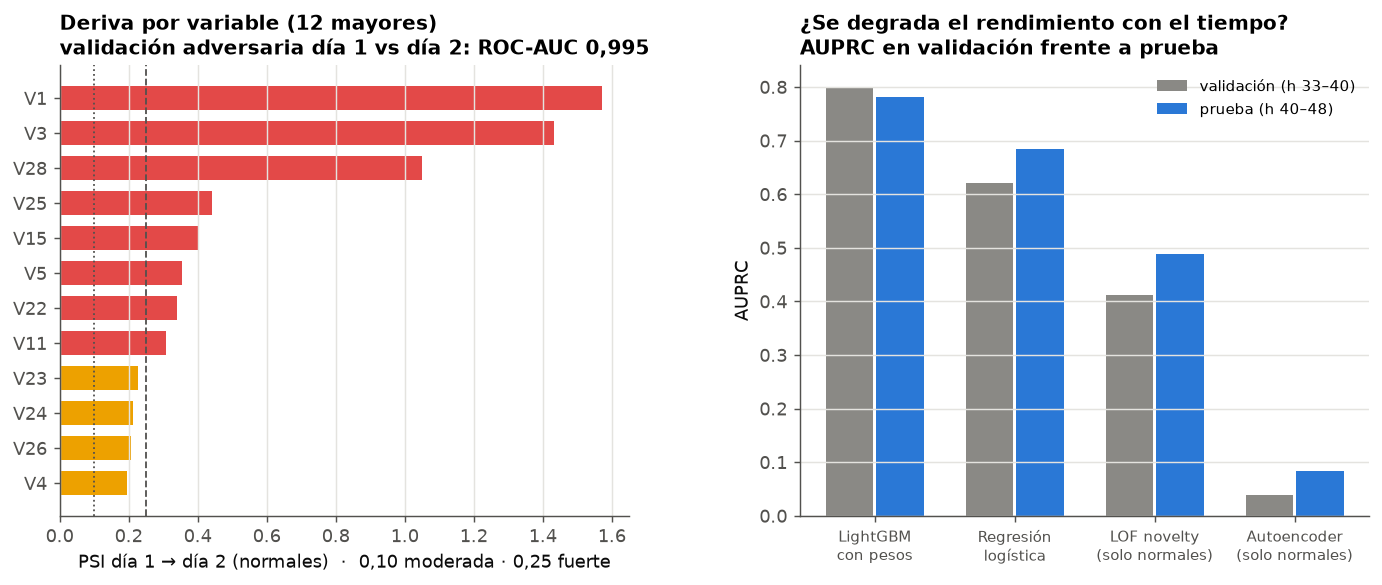

In [6]:
display(Image(filename=str(R / 'figures' / '09_deriva_temporal.png')))

**Lectura:** los dos días son casi perfectamente separables (ROC-AUC ≈ 0,995), sobre todo por `V1`, `V3` y `V28`: el PCA se ajustó sobre los dos días juntos y varias componentes recogen el ciclo y la tendencia temporal. Aun así, el rendimiento del modelo supervisado no cae entre validación y prueba, porque las variables que más derivan no son las que más separan el fraude (V14, V4, V12 según SHAP).